### Общая нумерация: **задача 6** Затухание (сравнение сигнала с учётом затухания и без)

#### Пересечение луча и сферы
##### Луч из точки $\vec{r}_0$ в направлении $\vec{d}$ $$\vec{r}(t) = \vec{r}_0 + t\cdot\vec{d}$$
##### Уравнение на принадлежность сфере радиусом $R$ с центром в $\vec{p}$ $$(\vec{r}(t) - \vec{p})^2 = R^2$$ $$(\vec{r}_0 - \vec{p} + t\cdot\vec{d})^2 = R^2 $$
##### $$t^2 + t\cdot 2((\vec{r}_0 - \vec{p}) , \vec{d}) + (\vec{r}_0 - \vec{p})^2 - R^2 = 0$$
##### Ищем только одно значение t, соответствующее направлению $\vec{d}$ $$t = -((\vec{r}_0 - \vec{p}) , \vec{d}) + \sqrt{((\vec{r}_0 - \vec{p}) , \vec{d})^2 - ((\vec{r}_0 - \vec{p})^2 - R^2)}$$

##### Частный случай: $(\vec{r}_0 - \vec{p}) = \vec{0} \rightarrow t = R$


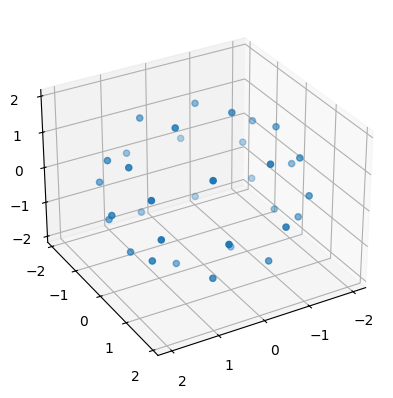

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ipynb.fs.full.Task2_Detector import Detector
from ipynb.fs.full.Task1_Source import Source as SourceGen

def points_of_photons_intersection_with_sphere(position, directions, sphere_R: float, sphere_position: np.ndarray):
    """Function to find interstion of line and sphere points"""
    r0 = position
    d = directions
    p = sphere_position
    R2 = sphere_R**2

    scalar = d @ (r0-p)
    discriminant = scalar**2 - ((r0-p) @ (r0-p) - R2)
    mask = discriminant >= 0
    if not mask.any(): return np.empty((0, 3)) 
    t = -scalar[mask] + np.sqrt(discriminant[mask]) 
    return r0 + (d[mask].T * t).T , np.linalg.norm((d[mask].T * t).T, axis=1) # points of intersection with sphere, distance from start 

def get_FWHM(hist, bins):
    """Function for getting full width at half maximum of distribution"""
    x = (bins[1:] + bins[:-1])/2
    y = hist
    i = np.argmax(y)
    yh = y[i] / 2
    def interp(j):
        return x[j] + (yh - y[j]) * (x[j+1] - x[j]) / (y[j+1] - y[j])
    kl = np.where((y[:i] - yh) * (y[1:i+1] - yh) <= 0)[0]
    kr = np.where((y[i:-1] - yh) * (y[i+1:] - yh) <= 0)[0]
    xl = interp(kl[-1])       if kl.size else np.nan
    xr = interp(i + kr[0])    if kr.size else np.nan
    return xr - xl, xl, xr

#### Запуск одного события с $E = 1\, МэВ$
##### Ожидаемый полный заряд $$Q = a \cdot Y\cdot N\cdot\frac{r^2}{R^2}\cdot e^{-\frac{R}{\lambda_{abs}}}$$

In [3]:
det = Detector(N=40, position=(0.,0.,0.))
source = SourceGen(energy=1, position=(0.,0.,0.))
total_charge = 0
for photons_dir in source.generator:    
    intersection_points, traveled_paths = points_of_photons_intersection_with_sphere(source.position, photons_dir, det.R, det.position)
    hits_photons = det.points_are_in_pm(intersection_points, traveled_paths) # [om_id, weighted n photons in it]
    hits_phe = det.make_charge(hits_photons) # [om_id, phe]
    total_charge += hits_phe[:, 1].sum()
expected_charge = det.a * source.Y * det.N * det.r**2 / det.R**2 * np.exp(-det.R / 8)
print(f"Собранный заряд в моделировании 1 события: {total_charge}\nОжидаемый заряд Q = {expected_charge:.1f}\nРазница {(total_charge - expected_charge):.1f}")

Собранный заряд в моделировании 1 события: 89.0
Ожидаемый заряд Q = 389.4
Разница -300.4


#### Сделаем 1000 событий при источнике в 3-х разных точках внутри сферы детектора

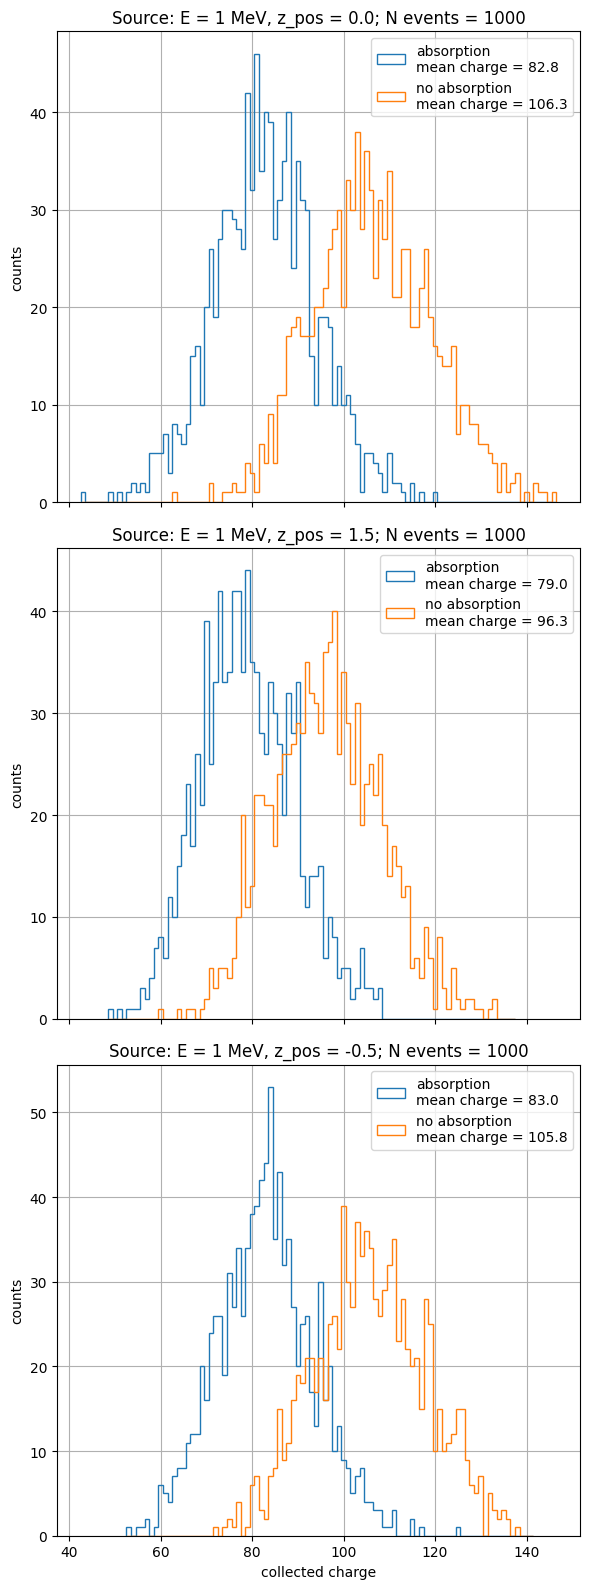

In [4]:
det = Detector(N=40, position=(0.,0.,0.))
N_events = 1000
z_positions = (0., 1.5, -0.5)

fig, axs = plt.subplots(len(z_positions), 1, figsize=(6, 5*len(z_positions)+1), sharex=True)
for i, z in enumerate(z_positions):
    ax = axs[i]
    total_charge = np.zeros((N_events, 2), dtype=np.int32)
    for e in range(N_events):
        source = SourceGen(energy=1, position=(0.,0.,z))
        for photons_dir in source.generator:    
            intersection_points, traveled_paths = points_of_photons_intersection_with_sphere(source.position, photons_dir, det.R, det.position)
            # photons absorption
            hits_photons = det.points_are_in_pm(intersection_points, traveled_paths) # [om_id, weighted n photons in it]
            hits_phe = det.make_charge(hits_photons) # [om_id, phe]
            total_charge[e, 0] += hits_phe[:, 1].sum() # here we save charge with photons absorption
            # no photons absorption
            hits_photons = det.points_are_in_pm(intersection_points, traveled_paths=None) # [om_id, n photons in it]
            hits_phe = det.make_charge(hits_photons) # [om_id, phe]
            total_charge[e, 1] += hits_phe[:, 1].sum() # here we save charge without photons absorption

    mean_charge = total_charge.mean(axis=0)

    ax.hist(total_charge[:, 0], bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', label=f"absorption\nmean charge = {mean_charge[0]:.1f}")
    ax.hist(total_charge[:, 1], bins=np.arange(total_charge.min()-0.5, total_charge.max()+0.5, 1), histtype='step', label=f"no absorption\nmean charge = {mean_charge[1]:.1f}")
    ax.set_title(f"Source: E = 1 MeV, z_pos = {source.position[2]}; N events = {N_events}")

    ax.set_ylabel("counts")
    ax.grid()
    ax.legend()
axs[len(z_positions)-1].set_xlabel("collected charge")
plt.tight_layout()